# Data summary of five FLUXNET towers

## Introduction and data

This report summarises FLUXNET data from five eddy-covariance towers: CA-TPD, US-UiA, CN-Dsh, CH-Lae and FI-Var. It covers site characteristics, data coverage, meteorological and flux variables, daily carbon fluxes, seasonal diurnal cycles, energy-balance closure and a comparison of carbon fluxes.

The analysis uses the five FLUXNET product ZIP files in `data/raw` and the metadata snapshot `data/snapshots/fluxnet_shuttle_snapshot_20261113T102619.csv`. The ZIP files are read directly; their contents are not modified. Run the notebook from the repository root.

## Methods

Half-hourly data are read from the `FLUXMET_HH` files. The missing-value code `-9999` is interpreted as missing, and timestamps are parsed from `TIMESTAMP_START`. The analysis uses `NEE_VUT_REF` (variable u* threshold product), `GPP_NT_VUT_REF` and `RECO_NT_VUT_REF` (nighttime-partitioning products), as well as the meteorological and energy-flux variables listed below.

Daily carbon fluxes are calculated by averaging half-hourly observations by day and applying the assignment conversion factor of 1.0378 to obtain g C m⁻² d⁻¹. Precipitation (`P_F`) is summarised as annual sums; its missing percentage is calculated from the half-hourly records. All other summary statistics are calculated from half-hourly observations.

The notebook requires `pandas`, `numpy`, `matplotlib`, `seaborn`, `geopandas` and `scipy`. The world map retrieves Natural Earth boundaries from a public URL, so an internet connection is required for that cell. The five ZIP files and metadata snapshot must be present in the paths above.

In [1]:
import pandas as pd
import numpy as np
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from scipy.stats import linregress

zip_files = sorted(Path("data/raw").glob("*.zip"))
snapshot_file = Path("data/snapshots/fluxnet_shuttle_snapshot_20261113T102619.csv")

if len(zip_files) != 5:
    raise FileNotFoundError(
        f"Expected five FLUXNET ZIP files in data/raw, found {len(zip_files)}."
    )
if not snapshot_file.exists():
    raise FileNotFoundError(f"Metadata snapshot not found: {snapshot_file}")

print("Number of ZIP files:", len(zip_files))
for zip_file in zip_files:
    print(" -", zip_file.name)


Number of ZIP files: 5
 - AMF_CA-TPD_FLUXNET_2012-2023_v1.3_r1.zip
 - AMF_US-UiA_FLUXNET_2008-2024_v1.3_r1.zip
 - CNF_CN-Dsh_FLUXNET_2013-2024_v1.3_r1.zip
 - EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1.zip
 - ICOS_FI-Var_FLUXNET_2016-2025_v1.3_r1.zip


In [2]:
snapshot_file = Path("data/snapshots/fluxnet_shuttle_snapshot_20261113T102619.csv")

snapshot = pd.read_csv(snapshot_file)

print(snapshot.shape)
print(snapshot.columns.tolist())
print(snapshot.head())

(783, 18)
['data_hub', 'site_id', 'site_name', 'location_lat', 'location_long', 'igbp', 'network', 'team_member_name', 'team_member_role', 'team_member_email', 'first_year', 'last_year', 'download_link', 'fluxnet_product_name', 'product_citation', 'product_id', 'oneflux_code_version', 'product_source_network']
    data_hub site_id                   site_name  location_lat  location_long  \
0  AmeriFlux  AR-Bal                 Balcarce BA      -37.7596       -58.3024   
1  AmeriFlux  AR-CCa  Carlos Casares agriculture      -35.6210       -61.3181   
2  AmeriFlux  AR-CCg    Carlos Casares grassland      -35.9244       -61.1855   
3  AmeriFlux  AR-TF1                Rio Moat bog      -54.9733       -66.7335   
4  AmeriFlux  AR-TF2                Rio Pipo bog      -54.8269       -68.4549   

  igbp    network                                   team_member_name  \
0  CRO  AmeriFlux  Maria Isabel Gassmann;Natalia Edith Tonti;Nahu...   
1  CRO  AmeriFlux     Gabriela Posse;Patricio Oricchio;Kl

In [3]:
def read_hh(zip_file):
    keep = [
        "TIMESTAMP_START", "TIMESTAMP_END",
        "TA_F", "SW_IN_F", "VPD_F", "P_F",
        "NETRAD", "G_F_MDS",
        "H_F_MDS", "H_F_MDS_QC",
        "LE_F_MDS", "LE_F_MDS_QC",
        "NEE_VUT_REF", "NEE_VUT_REF_QC",
        "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"
    ]

    with zipfile.ZipFile(zip_file) as z:
        hh_name = [
            n for n in z.namelist()
            if "FLUXMET_HH" in n
        ][0]

        with z.open(hh_name) as f:
            hh = pd.read_csv(
                f,
                na_values=[-9999],
                usecols=lambda c: c in keep,
                dtype={
                    "TIMESTAMP_START": str,
                    "TIMESTAMP_END": str
                }
            )

    hh["time"] = pd.to_datetime(
        hh["TIMESTAMP_START"],
        format="%Y%m%d%H%M"
    )

    hh["site"] = Path(zip_file).name.split("_")[1]

    return hh

In [4]:
all_hh = pd.concat(
    [read_hh(z) for z in zip_files],
    ignore_index=True
)

print(all_hh.shape)
print(all_hh["site"].value_counts())

(1262400, 18)
site
CH-Lae    368208
US-UiA    298080
CA-TPD    210384
CN-Dsh    210384
FI-Var    175344
Name: count, dtype: int64


## C1 – Site overview

In [7]:
# Select metadata for the five sites in the half-hourly dataset
site_order = ["CA-TPD", "US-UiA", "CN-Dsh", "CH-Lae", "FI-Var"]

site_info = snapshot[
    snapshot["site_id"].isin(all_hh["site"].unique())
].copy()

# Keep one metadata row per site and sort sites consistently
site_info = (
    site_info
    .drop_duplicates(subset="site_id")
)

site_info["site_id"] = pd.Categorical(
    site_info["site_id"],
    categories=site_order,
    ordered=True
)

site_info = (
    site_info
    .sort_values("site_id")
    .reset_index(drop=True)
)

display(site_info)

,data_hub,site_id,site_name,location_lat,location_long,igbp,network,team_member_name,team_member_role,team_member_email,first_year,last_year,download_link,fluxnet_product_name,product_citation,product_id,oneflux_code_version,product_source_network
0,AmeriFlux,CA-TPD,Ontario - Turkey Point Mature Deciduous,42.635300,-80.557700,DBF,AmeriFlux;Fluxnet-Canada;Phenocam,M. Altaf Arain;Jason J. Brodeur,PI;DataManager,arainm@mcmaster.ca;brodeujj@mcmaster.ca,2012,2023,https://ftp.fluxdata.org/.ameriflux_downloads/...,AMF_CA-TPD_FLUXNET_2012-2023_v1.3_r1.zip,"M. Altaf Arain (2025), AmeriFlux FLUXNET-1F CA...",10.17190/AMF/1881567,v1.3,AMF
1,AmeriFlux,US-UiA,University of Illinois Switchgrass,40.064600,-88.196100,CRO,AmeriFlux,Carl J Bernacchi;Bethany J Blakely;Caitlin E M...,PI;FluxContact;FluxContact;FluxContact;Technician,bernacch@illinois.edu;bethany.j.blakely@gmail....,2008,2024,https://ftp.fluxdata.org/.ameriflux_downloads/...,AMF_US-UiA_FLUXNET_2008-2024_v1.3_r1.zip,"Carl Bernacchi, Bethany Blakely, Caitlin Moore...",10.17190/AMF/3027336,v1.3,AMF
2,ICOS,CN-Dsh,Dashalong,38.839920,98.940600,GRA,ChinaFLUX,Tao Che;Shaomin Liu;Ziwei Xu,PI;PI;FluxContact,chetao@lzb.ac.cn;smliu@bnu.edu.cn;xuzw@bnu.edu.cn,2013,2024,https://data.icos-cp.eu/licence_accept?ids=%5B...,CNF_CN-Dsh_FLUXNET_2013-2024_v1.3_r1.zip,"Liu, S., Che, T., Xu, Z. (2026). Fluxnet Archi...",CuNYBsqS22epRiBFdnFTFpHD,v1.3,CNF
3,ICOS,CH-Lae,Laegern,47.478333,8.364389,MF,CarboEuropeIP;European Fluxes Database;GHG-Eur...,Lukas Hortnagl;Ankit Shekhar;Nina Buchmann;Lil...,FluxContact;FluxContact;PI;FluxContact;FluxCon...,lukas.hoertnagl@usys.ethz.ch;ankit.shekhar@usy...,2004,2024,https://data.icos-cp.eu/licence_accept?ids=%5B...,EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1.zip,"Buchmann, N., Hortnagl, L., Gharun, M., Etzold...",V_BAvTqbUIgSItmCcoHgP3Vy,v1.3,EUF
4,ICOS,FI-Var,Varrio,67.754900,29.610000,ENF,European Fluxes Database;ICOS,Pasi Kolari;Liisa Kulmala;Ganapati Sahoo;Pasi ...,PI;FluxContact;FluxContact;Technician;Technici...,pasi.kolari@helsinki.fi;liisa.kulmala@fmi.fi;g...,2016,2025,https://data.icos-cp.eu/licence_accept?ids=%5B...,ICOS_FI-Var_FLUXNET_2016-2025_v1.3_r1.zip,"Kolari, P., Aalto, P., Keronen, P., Kulmala, L...",yu-qbz8ScXeQLBioQVflVJIq,v1.3,ICOS


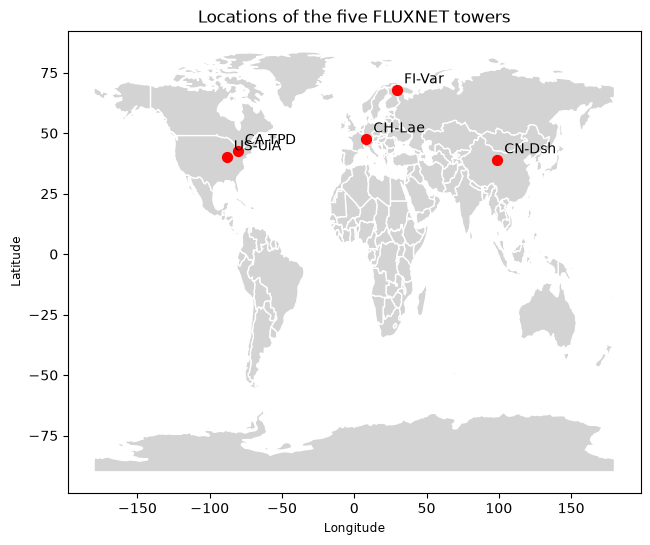

In [9]:
import matplotlib.pyplot as plt
import geopandas as gpd

world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
)

sites = gpd.GeoDataFrame(
    site_info,
    geometry=gpd.points_from_xy(
        site_info["location_long"],
        site_info["location_lat"]
    ),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(12, 6))

world.plot(ax=ax, color="lightgrey", edgecolor="white")
sites.plot(ax=ax, color="red", markersize=50)

for _, row in sites.iterrows():
    ax.annotate(
        row["site_id"],
        (row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title("Locations of the five FLUXNET towers")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

## C2 – Data coverage

Annual measured NEE coverage is calculated as the percentage of half-hourly records with `NEE_VUT_REF_QC == 0`. A site-year with no available QC flags is shown as unavailable, not as 0% measured coverage.

In [11]:
# Ensure time is datetime and extract year
all_hh["time"] = pd.to_datetime(all_hh["time"])
all_hh["year"] = all_hh["time"].dt.year

display(all_hh[["time", "year", "site"]].head())

coverage = (
    all_hh.groupby(["site", "year"])["NEE_VUT_REF_QC"]
    .apply(lambda x: (x == 0).mean() * 100 if x.notna().any() else float("nan"))
    .reset_index(name="Measured NEE (%)")
)

,time,year,site
0,2012-01-01 00:00:00,2012,CA-TPD
1,2012-01-01 00:30:00,2012,CA-TPD
2,2012-01-01 01:00:00,2012,CA-TPD
3,2012-01-01 01:30:00,2012,CA-TPD
4,2012-01-01 02:00:00,2012,CA-TPD


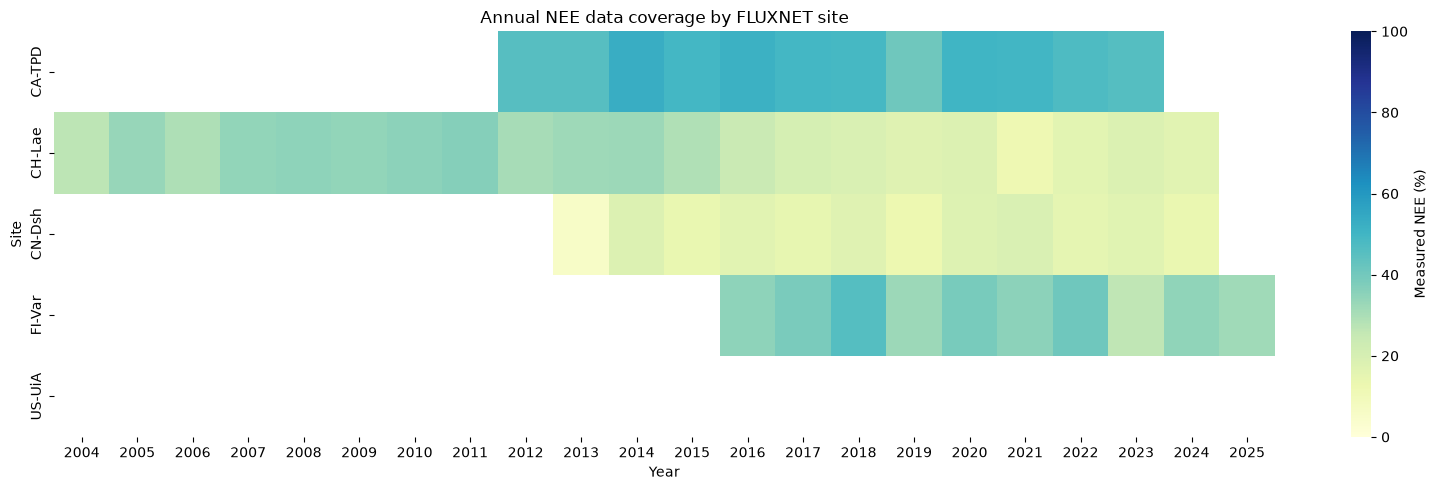

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

coverage_pivot = coverage.pivot(
    index="site",
    columns="year",
    values="Measured NEE (%)"
)

plt.figure(figsize=(16, 5))

sns.heatmap(
    coverage_pivot,
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    annot=False,
    cbar_kws={"label": "Measured NEE (%)"}
)

plt.title("Annual NEE data coverage by FLUXNET site")
plt.xlabel("Year")
plt.ylabel("Site")
plt.tight_layout()
plt.show()

In [13]:
coverage.loc[
    coverage["Measured NEE (%)"].idxmax()
]

site                   CA-TPD
year                     2014
Measured NEE (%)    52.899543
Name: 2, dtype: object

In [14]:
coverage.groupby("site")["Measured NEE (%)"].mean().sort_values(ascending=False)

site
CA-TPD    48.170248
FI-Var    36.076395
CH-Lae    26.319095
CN-Dsh    15.157893
US-UiA          NaN
Name: Measured NEE (%), dtype: float64

CA-TPD showed the highest average measured NEE coverage (48.2%), followed by FI-Var (36.1%), CH-Lae (26.3%) and CN-Dsh (15.2%). The highest individual site-year coverage was CA-TPD in 2014 (52.9%). US-UiA had no available NEE quality flags, so its measured NEE coverage is unavailable rather than 0%.

US-UiA had no available NEE quality flags, preventing an assessment of measured versus gap-filled NEE observations. Its coverage is therefore classified as unavailable rather than 0%.

## C3 – Summary statistics

In [16]:
variables = [
    "TA_F",
    "SW_IN_F",
    "VPD_F",
    "P_F",
    "NEE_VUT_REF",
    "GPP_NT_VUT_REF",
    "RECO_NT_VUT_REF",
    "H_F_MDS",
    "LE_F_MDS"
]

# Units are shown in the variable labels. P_F is summed annually.
units = {
    "TA_F": "°C",
    "SW_IN_F": "W m⁻²",
    "VPD_F": "hPa",
    "P_F": "mm (annual sum)",
    "NEE_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "GPP_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "RECO_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "H_F_MDS": "W m⁻²",
    "LE_F_MDS": "W m⁻²"
}

all_hh["year"] = all_hh["time"].dt.year
results = []

for site, data in all_hh.groupby("site"):
    for var in variables:
        missing = data[var].isna().mean() * 100

        if var == "P_F":
            # Sum half-hourly precipitation values within each year first.
            annual_sum = data.groupby("year")[var].sum(min_count=1)
            mean_value = annual_sum.mean()
            minimum = annual_sum.min()
            maximum = annual_sum.max()
        else:
            mean_value = data[var].mean()
            minimum = data[var].min()
            maximum = data[var].max()

        results.append({
            "Site": site,
            "Variable": f"{var} ({units[var]})",
            "Mean": mean_value,
            "Minimum": minimum,
            "Maximum": maximum,
            "Missing (%)": missing
        })

summary_stats = pd.DataFrame(results)
display(summary_stats.round(2))


,Site,Variable,Mean,Minimum,Maximum,Missing (%)
0,CA-TPD,TA_F (°C),10.05,-30.61,33.68,0.00
1,CA-TPD,SW_IN_F (W m⁻²),165.37,0.00,1105.52,0.00
2,CA-TPD,VPD_F (hPa),3.79,0.00,34.96,0.00
3,CA-TPD,P_F (mm (annual sum)),915.38,750.00,991.40,0.00
4,CA-TPD,NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),-0.51,-71.75,44.33,0.00
5,CA-TPD,GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),3.86,-41.61,75.06,0.00
6,CA-TPD,RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),3.34,0.00,14.50,0.00
7,CA-TPD,H_F_MDS (W m⁻²),27.27,-199.50,734.39,0.00
8,CA-TPD,LE_F_MDS (W m⁻²),31.08,-93.40,601.11,0.00
9,CH-Lae,TA_F (°C),8.90,-17.20,33.56,0.00


In [17]:
all_hh.groupby(["site", "year"]).size().groupby("site").agg(
    min_rows="min",
    max_rows="max",
    mean_rows="mean"
)

,min_rows,max_rows,mean_rows
site,,,
CA-TPD,17520,17568,17532.000000
CH-Lae,17520,17568,17533.714286
CN-Dsh,17520,17568,17532.000000
FI-Var,17520,17568,17534.400000
US-UiA,17520,17568,17534.117647


The five sites show considerable differences in their climatic conditions and carbon and energy fluxes. Mean annual air temperature ranges from −3.35 °C at CN-Dsh to 11.70 °C at US-UiA. CN-Dsh also has the highest mean annual precipitation (2625 mm), whereas FI-Var has the lowest (560 mm). Mean NEE ranges from −0.70 to 0.01 µmol CO₂ m⁻² s⁻¹ among the four sites with available data. Data completeness varies between sites: CN-Dsh has comparatively high missing data for GPP and RECO, while US-UiA lacks NEE, GPP and RECO data entirely. Its sensible and latent heat flux data are also approximately 48% incomplete. These differences in data availability should be considered when comparing sites.

## C4 – Daily carbon fluxes

Half-hourly NEE, GPP and RECO are averaged by day. The resulting daily mean fluxes are converted to g C m⁻² d⁻¹ using the assignment conversion factor of 1.0378.

In [18]:
flux_variables = [
    "NEE_VUT_REF",
    "GPP_NT_VUT_REF",
    "RECO_NT_VUT_REF"
]

daily_flux = (
    all_hh
    .set_index("time")
    .groupby("site")[flux_variables]
    .resample("D")
    .mean()
    .reset_index()
)

# Convert from µmol m⁻² s⁻¹ to g C m⁻² d⁻¹
daily_flux[flux_variables] = daily_flux[flux_variables] * 1.0378

display(daily_flux.head())

,site,time,NEE_VUT_REF,GPP_NT_VUT_REF,RECO_NT_VUT_REF
0,CA-TPD,2012-01-01,1.302546,-0.081925,1.220722
1,CA-TPD,2012-01-02,0.924247,-0.004254,0.920960
2,CA-TPD,2012-01-03,0.936877,-0.409134,0.529260
3,CA-TPD,2012-01-04,1.170625,-0.286890,0.884672
4,CA-TPD,2012-01-05,0.882303,0.264851,1.147498


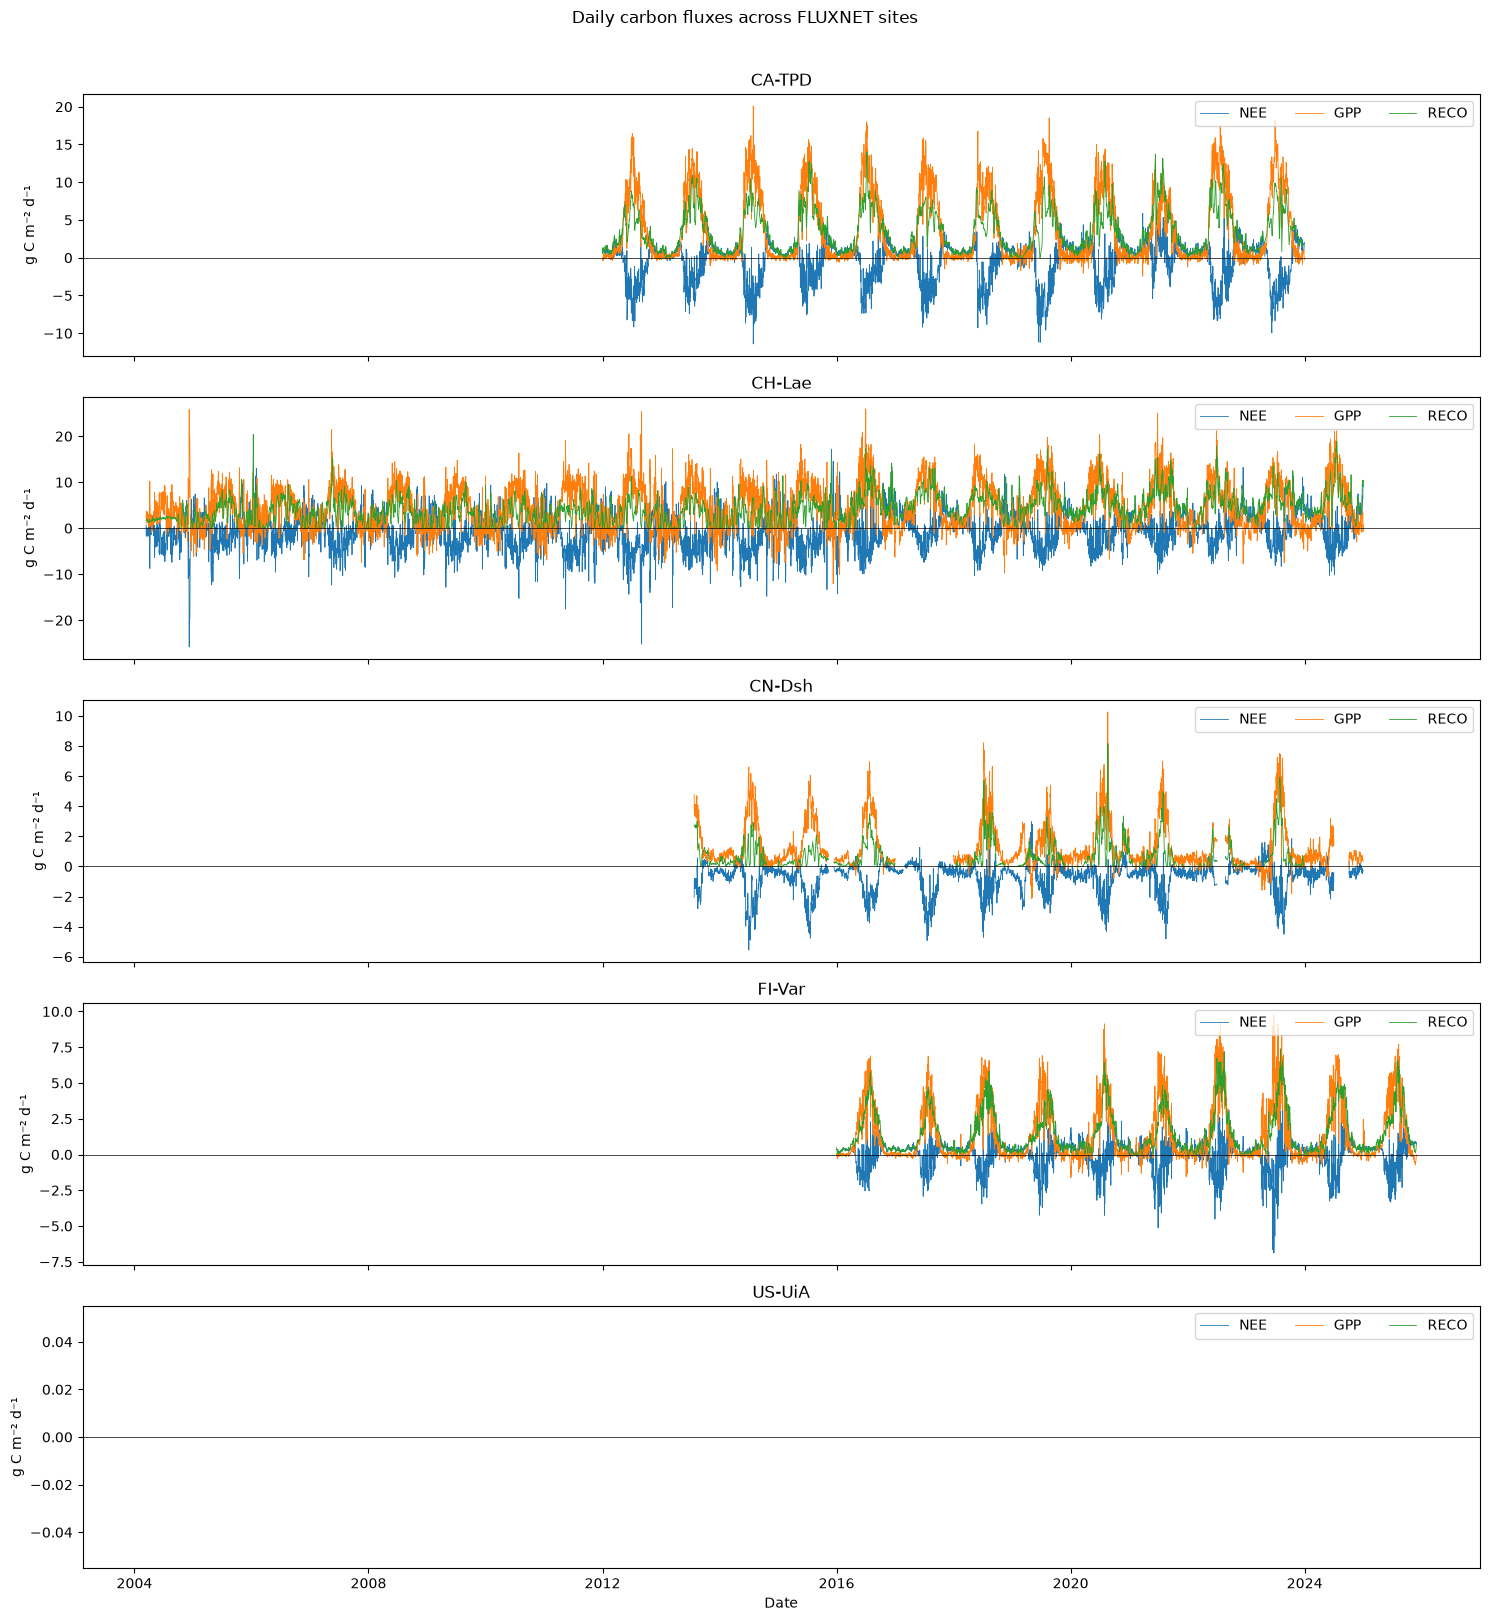

In [19]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(15, 16),
    sharex=True
)

for ax, (site, data) in zip(
    axes, daily_flux.groupby("site")
):
    ax.plot(data["time"], data["NEE_VUT_REF"],
            label="NEE", linewidth=0.6)
    ax.plot(data["time"], data["GPP_NT_VUT_REF"],
            label="GPP", linewidth=0.6)
    ax.plot(data["time"], data["RECO_NT_VUT_REF"],
            label="RECO", linewidth=0.6)

    ax.set_title(site)
    ax.set_ylabel("g C m⁻² d⁻¹")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.legend(loc="upper right", ncol=3)

axes[-1].set_xlabel("Date")

fig.suptitle("Daily carbon fluxes across FLUXNET sites", y=1.01)
plt.tight_layout()
plt.show()

### Validation against FLUXMET_DD

In [20]:
daily_reference = []
flux_variables = ["NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"]

for zip_file in zip_files:
    site = Path(zip_file).name.split("_")[1]

    with zipfile.ZipFile(zip_file) as z:
        dd_name = next(n for n in z.namelist() if "FLUXMET_DD" in n)

        # Check which columns are available
        with z.open(dd_name) as f:
            available_columns = pd.read_csv(f, nrows=0).columns.tolist()

        usecols = ["TIMESTAMP"] + [
            var for var in flux_variables
            if var in available_columns
        ]

        with z.open(dd_name) as f:
            dd = pd.read_csv(f, usecols=usecols, na_values=[-9999])

    # Add missing variables as empty columns
    for var in flux_variables:
        if var not in dd.columns:
            dd[var] = float("nan")

    dd["time"] = pd.to_datetime(
        dd["TIMESTAMP"].astype(str),
        format="%Y%m%d"
    )
    dd["site"] = site

    daily_reference.append(
        dd[["site", "time"] + flux_variables]
    )

daily_reference = pd.concat(daily_reference, ignore_index=True)

display(daily_reference.head())

,site,time,NEE_VUT_REF,GPP_NT_VUT_REF,RECO_NT_VUT_REF
0,CA-TPD,2012-01-01,1.302450,-0.081819,1.220630
1,CA-TPD,2012-01-02,0.924180,-0.003287,0.920893
2,CA-TPD,2012-01-03,0.940929,-0.411708,0.529221
3,CA-TPD,2012-01-04,1.170540,-0.285931,0.884608
4,CA-TPD,2012-01-05,0.882238,0.265177,1.147420


In [21]:
check = (
    daily_flux[daily_flux["site"] == "CA-TPD"]
    .merge(
        daily_reference[daily_reference["site"] == "CA-TPD"],
        on=["site", "time"],
        suffixes=("_HH", "_DD")
    )
)

for var in flux_variables:
    comparison = check[[f"{var}_HH", f"{var}_DD"]].dropna()

    difference = comparison[f"{var}_HH"] - comparison[f"{var}_DD"]

    print(f"\n{var}")
    print(f"Compared days: {len(comparison)}")
    print(f"Mean absolute difference: {difference.abs().mean():.6f}")
    print(f"Maximum absolute difference: {difference.abs().max():.6f}")


NEE_VUT_REF
Compared days: 4383
Mean absolute difference: 0.034436
Maximum absolute difference: 2.050450

GPP_NT_VUT_REF
Compared days: 4383
Mean absolute difference: 0.053270
Maximum absolute difference: 2.956970

RECO_NT_VUT_REF
Compared days: 4383
Mean absolute difference: 0.000252
Maximum absolute difference: 0.001056


In [22]:
for var in flux_variables:
    comparison = check[[f"{var}_HH", f"{var}_DD"]].dropna().copy()
    comparison["difference"] = (
        comparison[f"{var}_HH"] - comparison[f"{var}_DD"]
    )

    print(f"\n{var}")
    display(
        comparison.reindex(
            comparison["difference"].abs()
            .sort_values(ascending=False)
            .head(5).index
        )
    )


NEE_VUT_REF


,NEE_VUT_REF_HH,NEE_VUT_REF_DD,difference
4183,-3.751660,-5.80211,2.050450
3108,-4.767363,-6.75924,1.991877
2034,-3.945431,-5.87588,1.930449
3109,-3.477802,-5.06045,1.582648
3116,-6.121136,-7.57947,1.458334



GPP_NT_VUT_REF


,GPP_NT_VUT_REF_HH,GPP_NT_VUT_REF_DD,difference
2789,17.664470,14.70750,2.956970
2734,9.520443,6.60825,2.912193
2788,18.525244,15.87840,2.646844
2736,10.731498,8.18105,2.550448
2735,9.369956,6.82004,2.549916



RECO_NT_VUT_REF


,RECO_NT_VUT_REF_HH,RECO_NT_VUT_REF_DD,difference
1650,13.910256,13.9092,0.001056
1651,14.006013,14.0050,0.001013
1649,13.185184,13.1842,0.000984
1290,12.672267,12.6713,0.000967
3137,12.793860,12.7929,0.000960


In [23]:
# Inspect the five largest NEE differences
nee_check = check.copy()
nee_check["difference"] = (
    nee_check["NEE_VUT_REF_HH"] - nee_check["NEE_VUT_REF_DD"]
)

largest_days = nee_check.loc[
    nee_check["difference"].abs().nlargest(5).index,
    ["time", "NEE_VUT_REF_HH", "NEE_VUT_REF_DD", "difference"]
]

display(largest_days)

,time,NEE_VUT_REF_HH,NEE_VUT_REF_DD,difference
4183,2023-06-15,-3.751660,-5.80211,2.050450
3108,2020-07-05,-4.767363,-6.75924,1.991877
2034,2017-07-27,-3.945431,-5.87588,1.930449
3109,2020-07-06,-3.477802,-5.06045,1.582648
3116,2020-07-13,-6.121136,-7.57947,1.458334


In [24]:
dates_to_check = pd.to_datetime([
    "2023-06-15",
    "2020-07-05",
    "2017-07-27",
    "2020-07-06",
    "2020-07-13"
])

for date in dates_to_check:
    day = all_hh[
        (all_hh["site"] == "CA-TPD") &
        (all_hh["time"].dt.date == date.date())
    ]

    print(f"\n{date.date()}")
    print("Half-hourly records:", len(day))
    print("Available NEE values:", day["NEE_VUT_REF"].notna().sum())
    print("NEE quality flags:")
    display(day["NEE_VUT_REF_QC"].value_counts(dropna=False))


2023-06-15
Half-hourly records: 48
Available NEE values: 48
NEE quality flags:


NEE_VUT_REF_QC
2.0    24
3.0    12
0.0     7
1.0     5
Name: count, dtype: int64


2020-07-05
Half-hourly records: 48
Available NEE values: 48
NEE quality flags:


NEE_VUT_REF_QC
1.0    27
2.0    13
0.0     8
Name: count, dtype: int64


2017-07-27
Half-hourly records: 48
Available NEE values: 48
NEE quality flags:


NEE_VUT_REF_QC
1.0    41
0.0     4
2.0     3
Name: count, dtype: int64


2020-07-06
Half-hourly records: 48
Available NEE values: 48
NEE quality flags:


NEE_VUT_REF_QC
1.0    26
2.0    11
0.0    11
Name: count, dtype: int64


2020-07-13
Half-hourly records: 48
Available NEE values: 48
NEE quality flags:


NEE_VUT_REF_QC
0.0    27
1.0    21
Name: count, dtype: int64

In [25]:
nee_measured = (
    all_hh[all_hh["NEE_VUT_REF_QC"] == 0]
    .groupby(["site", all_hh["time"].dt.floor("D")])["NEE_VUT_REF"]
    .mean()
    .reset_index()
    .rename(columns={"time": "time", "NEE_VUT_REF": "NEE_measured"})
)

nee_comparison = nee_measured[
    nee_measured["site"] == "CA-TPD"
].merge(
    daily_reference[daily_reference["site"] == "CA-TPD"],
    on=["site", "time"]
)

nee_comparison["difference"] = (
    nee_comparison["NEE_measured"] * 1.0378
    - nee_comparison["NEE_VUT_REF"]
)

print("Mean absolute difference:")
print(nee_comparison["difference"].abs().mean())

Mean absolute difference:
3.337311495417179


Daily fluxes were calculated by averaging the half-hourly NEE, GPP and RECO measurements and converting the resulting mean fluxes to daily carbon units (g C m⁻² d⁻¹). The aggregation was validated against the corresponding FLUXMET_DD data for CA-TPD. RECO showed very close agreement (mean absolute difference: 0.0003 g C m⁻² d⁻¹), whereas NEE and GPP showed larger differences (0.0344 and 0.0533 g C m⁻² d⁻¹, respectively). Some individual days showed substantially larger deviations. Restricting NEE to observations with QC = 0 did not improve agreement. The discrepancies may reflect differences in processing or aggregation between the half-hourly and daily products.

## C5 – Seasonal diurnal cycles

Seasonal mean diurnal cycles are calculated by grouping half-hourly NEE and LE observations by site, season and hour of day. Seasons are assigned using site latitude, with seasons reversed in the Southern Hemisphere. All five towers in this dataset are in the Northern Hemisphere.

In [26]:
import numpy as np

# Add hour of day and month
all_hh["hour"] = all_hh["time"].dt.hour

all_hh["month"] = all_hh["time"].dt.month

# Site latitudes from the snapshot
site_latitudes = {
    "CA-TPD": 42.6353,
    "US-UiA": 40.0646,
    "CN-Dsh": 38.83992,
    "CH-Lae": 47.478333,
    "FI-Var": 67.7549
}

# Assign seasons based on hemisphere
def get_season(row):
    month = row["month"]
    latitude = site_latitudes[row["site"]]

    if latitude >= 0:  # Northern Hemisphere
        if month in [12, 1, 2]:
            return "Winter"
        elif month in [3, 4, 5]:
            return "Spring"
        elif month in [6, 7, 8]:
            return "Summer"
        else:
            return "Autumn"

    else:  # Southern Hemisphere
        if month in [6, 7, 8]:
            return "Winter"
        elif month in [9, 10, 11]:
            return "Spring"
        elif month in [12, 1, 2]:
            return "Summer"
        else:
            return "Autumn"

all_hh["season"] = all_hh.apply(get_season, axis=1)

display(all_hh[["site", "time", "hour", "season"]].head())

,site,time,hour,season
0,CA-TPD,2012-01-01 00:00:00,0,Winter
1,CA-TPD,2012-01-01 00:30:00,0,Winter
2,CA-TPD,2012-01-01 01:00:00,1,Winter
3,CA-TPD,2012-01-01 01:30:00,1,Winter
4,CA-TPD,2012-01-01 02:00:00,2,Winter


In [27]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]

diurnal = (
    all_hh
    .groupby(["site", "season", "hour"])[
        ["NEE_VUT_REF", "LE_F_MDS"]
    ]
    .mean()
    .reset_index()
)

diurnal["season"] = pd.Categorical(
    diurnal["season"],
    categories=season_order,
    ordered=True
)

display(diurnal.head(12))

,site,season,hour,NEE_VUT_REF,LE_F_MDS
0,CA-TPD,Autumn,0,3.342061,4.251716
1,CA-TPD,Autumn,1,3.404199,4.095116
2,CA-TPD,Autumn,2,3.417887,4.127421
3,CA-TPD,Autumn,3,3.377171,3.693816
4,CA-TPD,Autumn,4,3.396487,3.828806
5,CA-TPD,Autumn,5,3.352975,3.347980
6,CA-TPD,Autumn,6,2.583544,3.608082
7,CA-TPD,Autumn,7,-0.358504,9.656848
8,CA-TPD,Autumn,8,-2.853970,28.960253
9,CA-TPD,Autumn,9,-4.724038,55.863209


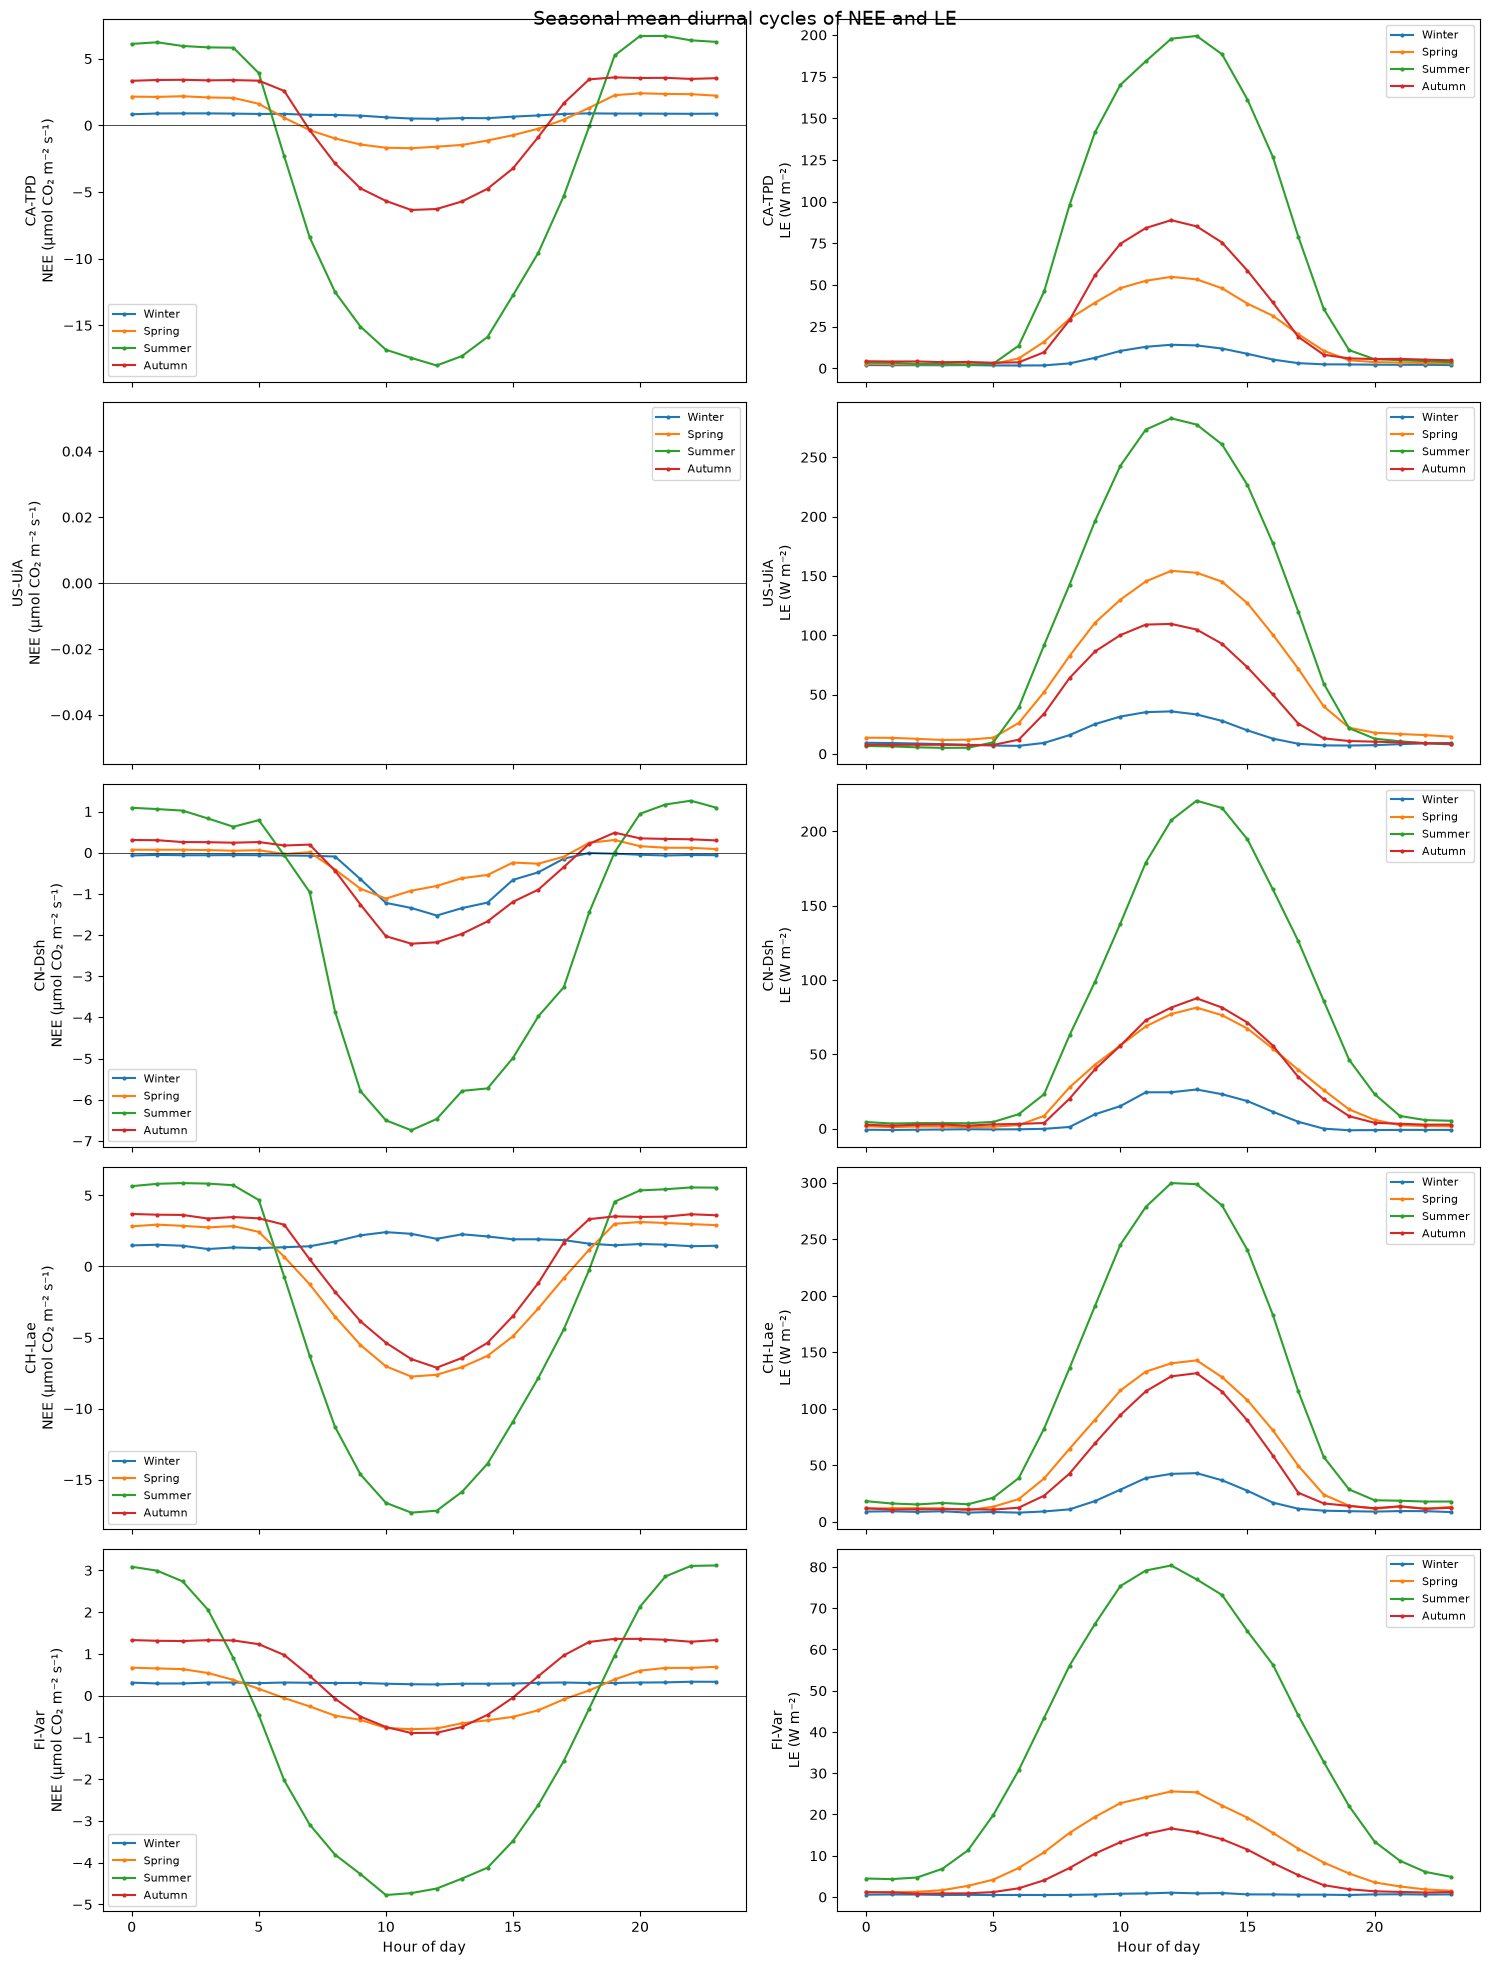

In [28]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(15, 20),
    sharex=True
)

for i, site in enumerate(site_latitudes.keys()):
    site_data = diurnal[diurnal["site"] == site]

    for season in season_order:
        season_data = site_data[site_data["season"] == season]

        axes[i, 0].plot(
            season_data["hour"],
            season_data["NEE_VUT_REF"],
            label=season,
            marker="o",
            markersize=2
        )

        axes[i, 1].plot(
            season_data["hour"],
            season_data["LE_F_MDS"],
            label=season,
            marker="o",
            markersize=2
        )

    axes[i, 0].set_ylabel(
        f"{site}\nNEE (µmol CO₂ m⁻² s⁻¹)"
    )
    axes[i, 1].set_ylabel(
        f"{site}\nLE (W m⁻²)"
    )

    axes[i, 0].axhline(0, color="black", linewidth=0.5)

    axes[i, 0].legend(fontsize=8)
    axes[i, 1].legend(fontsize=8)

axes[-1, 0].set_xlabel("Hour of day")
axes[-1, 1].set_xlabel("Hour of day")

fig.suptitle(
    "Seasonal mean diurnal cycles of NEE and LE",
    fontsize=14
)

plt.tight_layout()
plt.show()

Seasonal mean diurnal cycles were calculated by grouping half-hourly NEE and LE observations by site, season and hour of day. Seasonal means were calculated using all available observations, without additional QC filtering. Seasons were assigned according to site latitude: December–February (winter), March–May (spring), June–August (summer) and September–November (autumn) in the Northern Hemisphere, with reversed seasons in the Southern Hemisphere. All five towers are located in the Northern Hemisphere.

## C6 – Energy balance and site comparison

### C6.1 – Energy balance closure

CA-TPD is used for the energy-balance analysis because it has available NETRAD, G, H and LE data. Only half-hours where both H and LE have QC = 0 are retained; observations with missing NETRAD or G are also excluded. Available energy is calculated as NETRAD − G, and turbulent flux as H + LE.

In [29]:
energy_variables = [
    "NETRAD", "G_F_MDS",
    "H_F_MDS", "H_F_MDS_QC",
    "LE_F_MDS", "LE_F_MDS_QC"
]

for site, data in all_hh.groupby("site"):
    print(f"\n{site}")
    display(
        (data[energy_variables].notna().mean() * 100).round(1)
    )


CA-TPD


NETRAD          88.0
G_F_MDS         99.9
H_F_MDS        100.0
H_F_MDS_QC     100.0
LE_F_MDS       100.0
LE_F_MDS_QC    100.0
dtype: float64


CH-Lae


NETRAD          0.0
G_F_MDS         0.0
H_F_MDS        99.1
H_F_MDS_QC     99.1
LE_F_MDS       99.0
LE_F_MDS_QC    99.0
dtype: float64


CN-Dsh


NETRAD         57.6
G_F_MDS        92.3
H_F_MDS        95.3
H_F_MDS_QC     95.3
LE_F_MDS       94.2
LE_F_MDS_QC    94.2
dtype: float64


FI-Var


NETRAD          83.4
G_F_MDS        100.0
H_F_MDS         99.1
H_F_MDS_QC      99.1
LE_F_MDS        99.1
LE_F_MDS_QC     99.1
dtype: float64


US-UiA


NETRAD         49.9
G_F_MDS        36.6
H_F_MDS        51.8
H_F_MDS_QC     51.8
LE_F_MDS       51.8
LE_F_MDS_QC    51.8
dtype: float64

In [30]:
energy = all_hh[
    (all_hh["site"] == "CA-TPD") &
    (all_hh["H_F_MDS_QC"] == 0) &
    (all_hh["LE_F_MDS_QC"] == 0)
].copy()

energy["available_energy"] = (
    energy["NETRAD"] - energy["G_F_MDS"]
)

energy["turbulent_flux"] = (
    energy["H_F_MDS"] + energy["LE_F_MDS"]
)

energy = energy.dropna(
    subset=["available_energy", "turbulent_flux"]
)

print("Valid half-hours:", len(energy))
print("Total CA-TPD half-hours:", len(all_hh[all_hh["site"] == "CA-TPD"]))

Valid half-hours: 160091
Total CA-TPD half-hours: 210384


Slope: 0.615
Intercept: -0.598
R²: 0.876


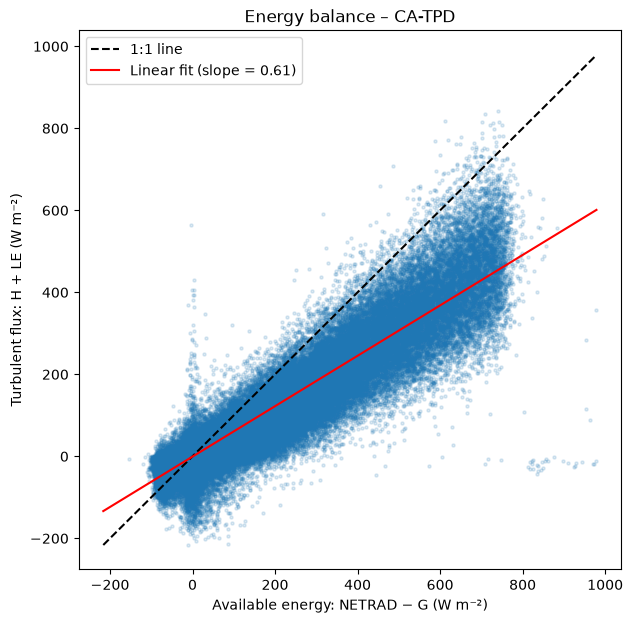

In [31]:

x = energy["available_energy"]
y = energy["turbulent_flux"]

regression = linregress(x, y)

print(f"Slope: {regression.slope:.3f}")
print(f"Intercept: {regression.intercept:.3f}")
print(f"R²: {regression.rvalue**2:.3f}")

# Scatterplot
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(x, y, alpha=0.15, s=5)

# 1:1 line
limits = [
    min(x.min(), y.min()),
    max(x.max(), y.max())
]
ax.plot(limits, limits, color="black", linestyle="--", label="1:1 line")

# Regression line
ax.plot(
    limits,
    regression.intercept + regression.slope * np.array(limits),
    color="red",
    label=f"Linear fit (slope = {regression.slope:.2f})"
)

ax.set_xlabel("Available energy: NETRAD − G (W m⁻²)")
ax.set_ylabel("Turbulent flux: H + LE (W m⁻²)")
ax.set_title("Energy balance – CA-TPD")
ax.legend()


The energy balance was evaluated for CA-TPD using half-hourly observations where both sensible and latent heat fluxes had QC = 0. Observations with missing NETRAD or G values were also excluded, leaving 160,091 half-hours. The linear regression of turbulent fluxes (H + LE) against available energy (NETRAD − G) yielded a slope of 0.615, an intercept of −0.598 W m⁻² and an R² of 0.876. The slope indicates an energy-balance closure of approximately 61.5%, with turbulent fluxes systematically lower than available energy.

### C6.2 – Comparison of carbon fluxes

Annual NEE is calculated by summing daily NEE values. Negative NEE indicates net ecosystem carbon uptake. Annual non-missing NEE coverage is calculated separately from measured coverage in C2: it counts all non-null NEE values, including gap-filled values.

In [32]:
annual_nee = (
    daily_flux
    .groupby(["site", daily_flux["time"].dt.year])["NEE_VUT_REF"]
    .sum(min_count=1)
    .reset_index(name="annual_NEE")
)

annual_nee = annual_nee.rename(columns={"time": "year"})

display(
    annual_nee.groupby("site")["annual_NEE"]
    .agg(["mean", "min", "max"])
    .round(1)
)

,mean,min,max
site,,,
CA-TPD,-191.9,-403.0,382.7
CH-Lae,-211.1,-679.7,352.3
CN-Dsh,-242.1,-352.9,-94.5
FI-Var,4.0,-75.1,38.3
US-UiA,NaN,NaN,NaN


In [33]:
annual_coverage = (
    all_hh.groupby(["site", "year"])["NEE_VUT_REF"]
    .agg(
        valid="count",
        total="size"
    )
    .reset_index()
)

annual_coverage["coverage_percent"] = (
    annual_coverage["valid"] /
    annual_coverage["total"] * 100
)

display(
    annual_coverage.groupby("site")["coverage_percent"]
    .agg(["mean", "min", "max"])
    .round(1)
)

# A site-year with no non-missing NEE values has unavailable coverage,
# rather than 0% coverage.
annual_coverage.loc[
    annual_coverage["valid"] == 0,
    "coverage_percent"
] = np.nan


,mean,min,max
site,,,
CA-TPD,100.0,100.0,100.0
CH-Lae,99.0,79.9,100.0
CN-Dsh,90.8,43.4,100.0
FI-Var,99.1,91.0,100.0
US-UiA,0.0,0.0,0.0


In [34]:
display(
    annual_coverage[
        annual_coverage["coverage_percent"] < 95
    ].sort_values(["site", "year"])
    .round(1)
)

,site,year,valid,total,coverage_percent
12,CH-Lae,2004,14040,17568,79.9
33,CN-Dsh,2013,7612,17520,43.4
35,CN-Dsh,2015,15901,17520,90.8
42,CN-Dsh,2022,15017,17520,85.7
44,CN-Dsh,2024,12995,17568,74.0
54,FI-Var,2025,15949,17520,91.0


In [35]:
seasonal_nee = (
    all_hh
    .groupby(["site", "season"])["NEE_VUT_REF"]
    .mean()
    .reset_index()
)

seasonal_pivot = seasonal_nee.pivot(
    index="site",
    columns="season",
    values="NEE_VUT_REF"
)

seasonal_amplitude = (
    seasonal_pivot.max(axis=1) - seasonal_pivot.min(axis=1)
).sort_values(ascending=False)

display(seasonal_pivot.round(2))
display(seasonal_amplitude.round(2))

season,Autumn,Spring,Summer,Winter
site,,,,
CA-TPD,0.21,0.62,-3.59,0.78
CH-Lae,0.27,-0.88,-3.22,1.70
CN-Dsh,-0.42,-0.19,-1.90,-0.39
FI-Var,0.60,0.01,-0.85,0.30
US-UiA,NaN,NaN,NaN,NaN


site
CH-Lae    4.92
CA-TPD    4.37
CN-Dsh    1.71
FI-Var    1.44
US-UiA     NaN
dtype: float64

The five towers show substantial differences in their carbon fluxes and seasonal dynamics. CN-Dsh had the most negative mean annual NEE sum (−242.1 g C m⁻² yr⁻¹), followed by CH-Lae (−211.1) and CA-TPD (−191.9), indicating stronger net carbon uptake at CN-Dsh. However, this comparison should be interpreted cautiously because CN-Dsh had incomplete NEE coverage, particularly in 2013 (43.4%). US-UiA could not be included in the carbon flux comparison because its NEE, GPP and RECO data were unavailable. CH-Lae showed the largest seasonal NEE amplitude (4.92 µmol CO₂ m⁻² s⁻¹), followed by CA-TPD (4.37), with both sites exhibiting strong summer carbon uptake. CN-Dsh was notable for showing negative mean NEE in all four seasons. The proportion of gap-filled NEE observations (QC 1–3) ranged from 51.8% at CA-TPD to 75.6% at CN-Dsh; CH-Lae and FI-Var had 72.8% and 63.0%, respectively. US-UiA had no NEE QC data available.

#### NEE quality-flag distribution

The following table shows the percentage of half-hourly records in each `NEE_VUT_REF_QC` category, including missing QC flags. QC = 0 is treated as measured; QC categories 1–3 are grouped as gap-filled for this comparison. Missing QC flags are shown separately.

In [36]:
qc_shares_all = (
    all_hh.groupby("site")["NEE_VUT_REF_QC"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .rename("percentage")
    .reset_index()
)

display(
    qc_shares_all.pivot(
        index="site",
        columns="NEE_VUT_REF_QC",
        values="percentage"
    ).round(1)
)

NEE_VUT_REF_QC,NaN,0.0,1.0,2.0,3.0
site,,,,,
CA-TPD,NaN,48.2,42.0,8.4,1.4
CH-Lae,1.0,26.3,63.9,7.7,1.2
CN-Dsh,9.2,15.2,55.5,11.4,8.7
FI-Var,0.9,36.1,57.6,3.7,1.7
US-UiA,100.0,NaN,NaN,NaN,NaN


## Acknowledgements

FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service.

## Citations

- Altaf Arain, M. (2025). *AmeriFlux FLUXNET-1F CA-TPD Ontario – Turkey Point Mature Deciduous* (Version v1.3_r1) [Dataset]. AmeriFlux AMP. https://doi.org/10.17190/AMF/1881567
- Bernacchi, C., Blakely, B., Moore, C., & Pederson, T. (2026). *AmeriFlux FLUXNET-1F US-UiA University of Illinois Switchgrass* (Version v1.3_r1) [Dataset]. AmeriFlux AMP. https://doi.org/10.17190/AMF/3027336
- Buchmann, N., Hortnagl, L., Gharun, M., Etzold, S., Paul-Limoges, E., Shekhar, A., Scapucci, L., Baur, T., & Meier, P. (2025). *Fluxnet Archive Product from Laegern, 2004–2024* [Dataset]. FLUXNET. https://hdl.handle.net/11676/V_BAvTqbUIgSItmCcoHgP3Vy
- Kolari, P., Aalto, P., Keronen, P., Kulmala, L., & Sahoo, G. (2026). *Fluxnet Archive Product from Varrio, 2016–2025* [Dataset]. FLUXNET. https://hdl.handle.net/11676/yu-qbz8ScXeQLBioQVflVJIq
- Liu, S., Che, T., & Xu, Z. (2026). *Fluxnet Archive Product from Dashalong, 2013–2024* [Dataset]. FLUXNET. https://hdl.handle.net/11676/CuNYBsqS22epRiBFdnFTFpHD
- Pastorello, G., Trotta, C., Canfora, E., et al. (2020). The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data. *Scientific Data, 7*, Article 225. https://doi.org/10.1038/s41597-020-0534-3